# Series temporales

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

### Plotear series temporales

In [2]:
retornos = pd.read_csv('retornos.csv')

In [4]:
retornos.head(10)

,Retornos
0,0.000000
1,0.400157
2,1.258848
3,3.122087
4,4.053019
5,1.859835
6,2.251973
7,1.425024
8,0.894298
9,1.036607


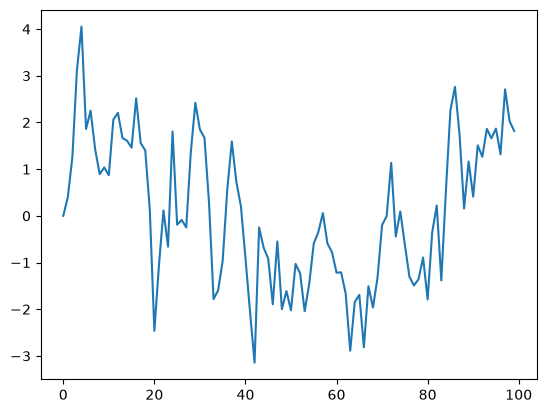

In [5]:
# Plotear serie temporal
plt.plot(retornos)
plt.show()

### Autocorrelación (ACF)

* ¿Muestran los valores de la serie temporal **correlación** con sus valores un periodo antes? ¿O con sus valores dos periodos antes?

In [7]:
# Calculamos los lags/rezagos 1 periodo antes y 2 periodos antes
retornos_lag_1 = retornos.shift(1)
retornos_lag_2 = retornos.shift(2)

In [8]:
# Calculamos la correlación
retornos_with_lags = pd.concat([retornos, retornos_lag_1, retornos_lag_2], axis=1)
retornos_with_lags.columns = ['retornos', 'retornos_lag_1', 'retornos_lag_2']
retornos_with_lags

,retornos,retornos_lag_1,retornos_lag_2
0,0.000000,NaN,NaN
1,0.400157,0.000000,NaN
2,1.258848,0.400157,0.000000
3,3.122087,1.258848,0.400157
4,4.053019,3.122087,1.258848
...,...,...,...
95,1.868678,1.660150,1.862548
96,1.318575,1.868678,1.660150
97,2.708873,1.318575,1.868678
98,2.023123,2.708873,1.318575


In [9]:
# Calculamos la correlación
retornos_with_lags.corr()

,retornos,retornos_lag_1,retornos_lag_2
retornos,1.000000,0.772792,0.606904
retornos_lag_1,0.772792,1.000000,0.769643
retornos_lag_2,0.606904,0.769643,1.000000


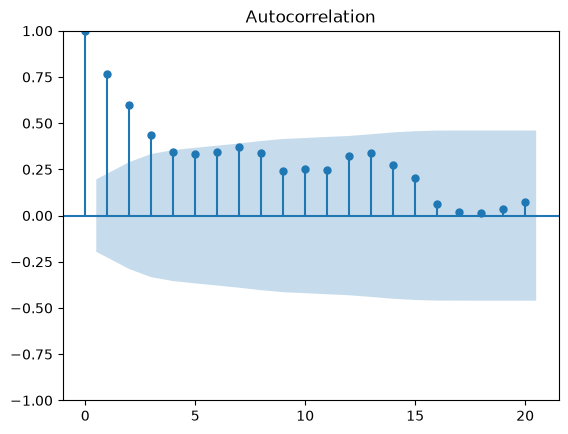

In [10]:
# Plotear ACF
plot_acf(retornos)
plt.show()

### Autocorrelación Parcial (PACF)

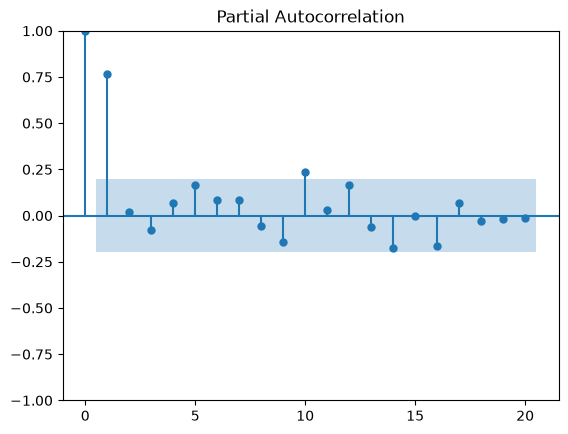

In [11]:
# Plotear PACF
plot_pacf(retornos)
plt.show()

### 🧩 Ejercicio
Sobre los datos `ventas_mensuales.csv`
* Plotea la serie temporal
* Plotea ACF, PACF
* ¿Qué depedencias hay entre los valores de la serie?

In [13]:
ventas = pd.read_csv('ventas_mensuales.csv')

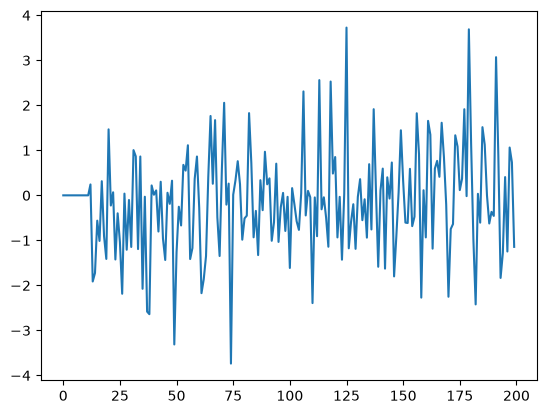

In [14]:
# Plotea la serie temporal
plt.plot(ventas)
plt.show()

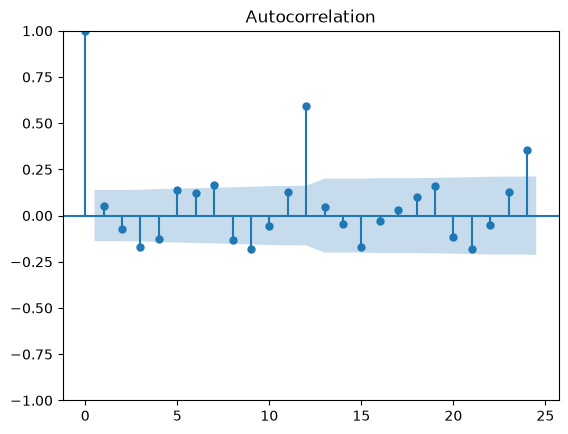

In [15]:
# Plotea ACF
plot_acf(ventas)
plt.show()

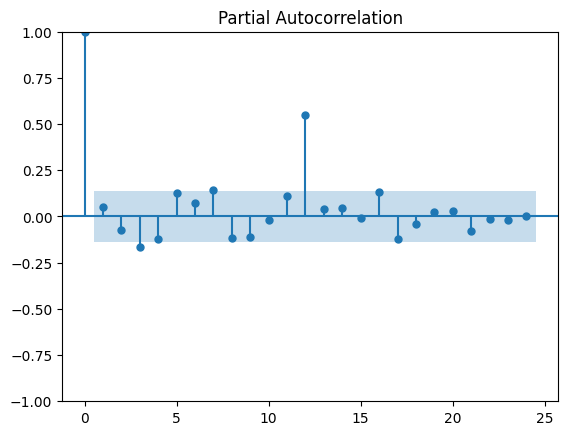

In [21]:
# Plotea PACF
plot_pacf(ventas)
plt.show()

In [22]:
# ¿Qué depedencias hay entre los valores de la serie? Dependencia anual!

### Primera diferencia
* Importar `sea_temperatures.csv`
* Plotear la ST y explicar por qué no es estacionaria.
* Usar la primera diferencia si es necesario para convertirla en estacionaria.

In [3]:
sea_temperatures = pd.read_csv('sea_temperatures.csv')

In [4]:
sea_temperatures.head()

,sea_temperatures
0,10.026375
1,10.460322
2,10.004854
3,10.395699
4,9.528367


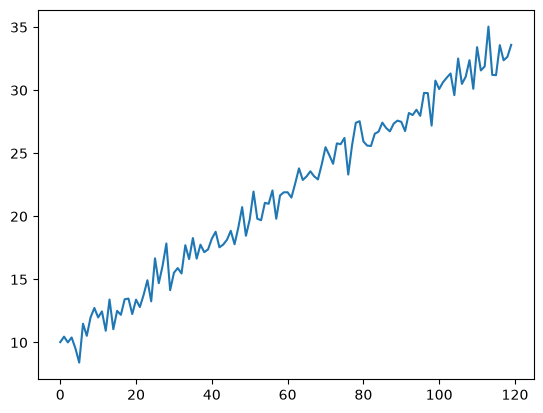

In [5]:
# Plotear la ST y explicar por qué no es estacionaria.
plt.plot(sea_temperatures)
plt.show()

In [6]:
# Aplicar primera diferencia a sea_temperatures (comportamiento aditivo)
sea_temperatures_diff = sea_temperatures.diff()

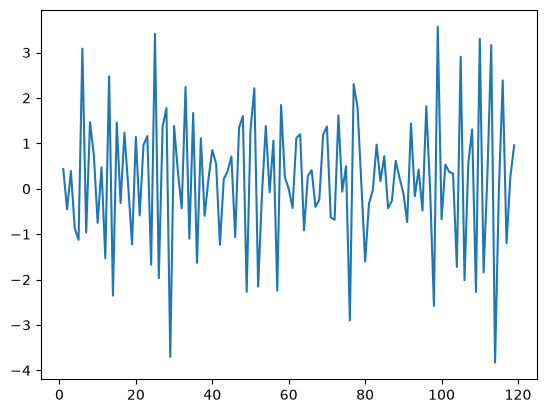

In [7]:
# Ploteo sea_temperatures_diff y ojalá sea estacionario
plt.plot(sea_temperatures_diff)
plt.show()

### Incremento porcentual
* Importar `pib.csv`
* Plotear la ST y decidir si es estacionaria.
* Usar el incremento porcentual si es necesario para convertirla en estacionaria.
* ¿La primera diferencia convierte la serie en estacionaria?

In [8]:
pib = pd.read_csv('pib.csv')

In [9]:
pib.head()

,pib
0,105.848758
1,115.732366
2,114.910892
3,100.672477
4,117.395572


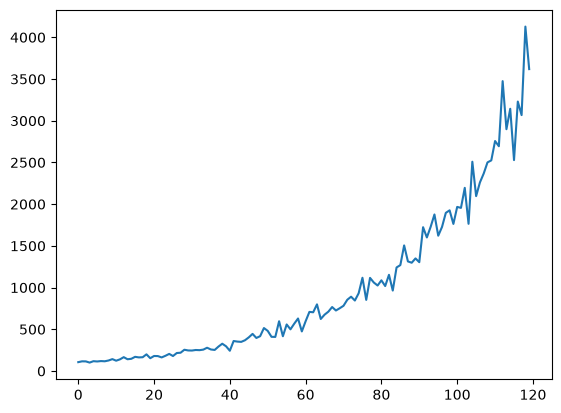

In [10]:
# Plotear la ST y decidir si es estacionaria.
plt.plot(pib)
plt.show()

In [11]:
pib_proportions = pib.pct_change()

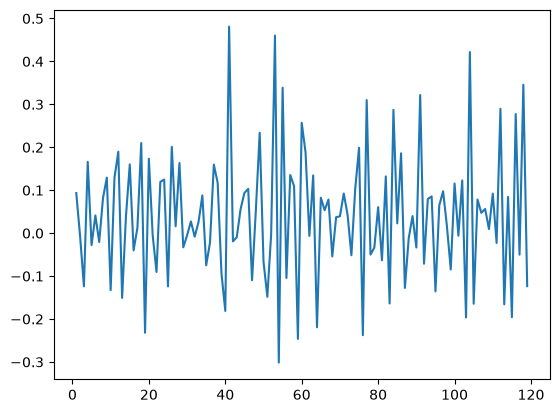

In [12]:
# El incremento porcentual puede convertir una ST exponencial en estacionaria
plt.plot(pib_proportions)
plt.show()

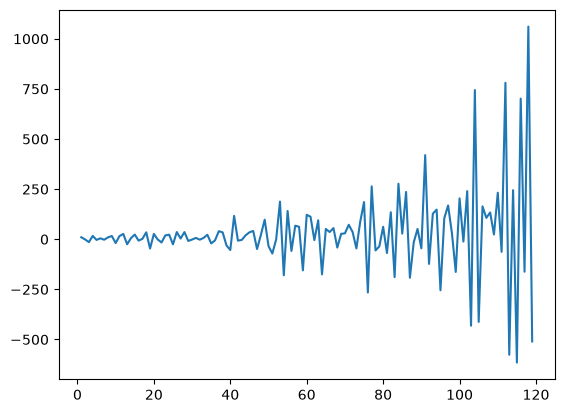

In [13]:
# La primera diferencia no sirve para convertir una ST con crecimiento exponencial en estacionaria
plt.plot(pib.diff())
plt.show()

### 🧩 Ejercicio
Sobre los datos de las cotizaciones de Apple (ticker 'AAPL') desde `start="2020-01-01"` hasta `end="2025-12-31"`
* Plotea el precio de cierre. Es el precio estacionario?
* En caso de no ser estacionario, cómo lo corrigirías?
* Plotea ACF y PACF para los retornos.

In [39]:
# Plotea el precio de cierre. Es el precio estacionario?

import yfinance as yf
prices = yf.download("AAPL", start="2020-01-01", end="2025-12-31")["Close"]

/tmp/ipykernel_10807/3905067957.py:5: FutureWarning: YF.download() has changed argument auto_adjust default to True
  prices = yf.download("AAPL", start="2020-01-01", end="2025-12-31")["Close"]
[*********************100%***********************]  1 of 1 completed


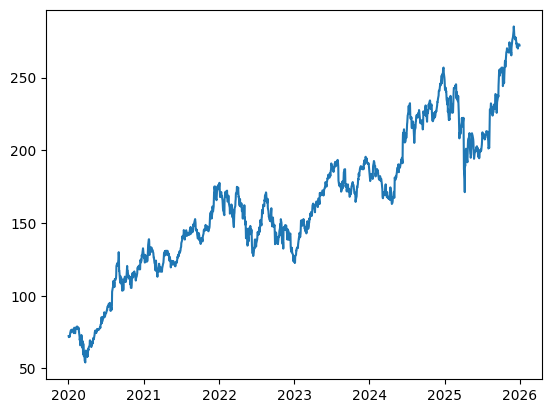

In [40]:
plt.plot(prices)
plt.show()

In [47]:
# En caso de no ser estacionario, cómo lo corrigirías?
returns = prices.pct_change().dropna()

In [48]:
returns.head()

Ticker,AAPL
Date,
2020-01-03,-0.009722
2020-01-06,0.007968
2020-01-07,-0.004703
2020-01-08,0.016086
2020-01-09,0.021241


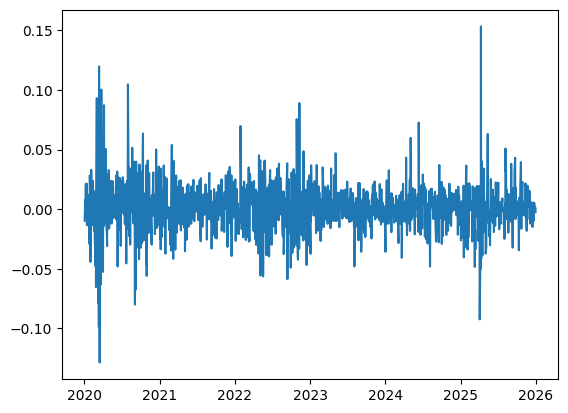

In [44]:
plt.plot(returns)
plt.show()

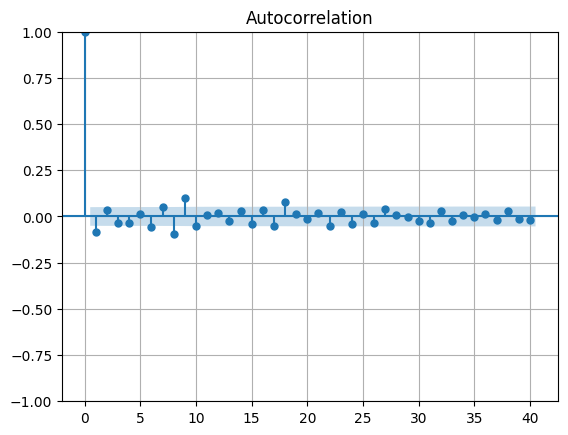

In [56]:
# Plotea ACF y PACF para los retornos
plot_acf(returns, lags = 40)
plt.grid(True)
plt.show()


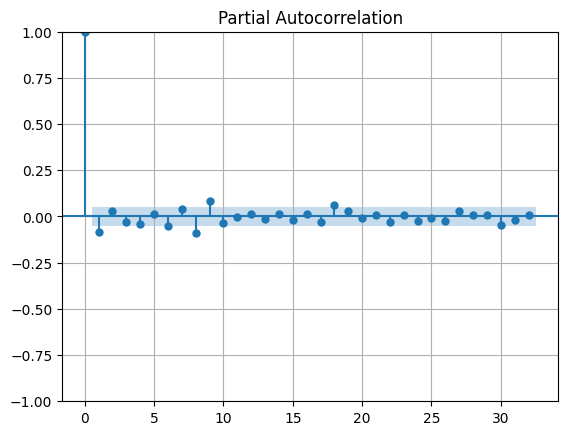

In [53]:
# Plotea ACF y PACF para los retornos
plot_pacf(returns)
plt.grid(True)
plt.show()